# Impact of AI Datacenters on Residential Electricity Costs
**Course:** CS 329E: Data Visualization  
**Group Number:** P29  
**Team Members:**  
- **Aadi Vasa** (UT EID: `adv982`)  
- **Jieun Lee** (UT EID: `jl83729`)  
- **Jahnavi Rayannavar** (UT EID: `jar23992`)  
**Date:** Fall 2026

---

### Project Goal & Core Hypothesis
**Core Research Question:** *Is the rapid, AI-driven buildout of hyperscale data centers in the United States measurably raising residential electricity bills for everyday consumers compared to demographically similar counties without them?*

**Hypothesis Testing:**
- **Null Hypothesis ($H_0$):** Hosting AI data centers has no measurable impact on local residential electricity price growth ($eta = 0$).
- **Alternative Hypothesis ($H_1$):** Surging power demand from AI data centers increases residential retail rates ($eta > 0$) by straining local grid capacity and accelerating capital spending.

### Methodological Summary
By linking county-level AI data center operational capacity ($MW$) to annual federal **EIA-861 Sales to Ultimate Customers** (2018–2024), **U.S. Census Bureau population estimates**, and **USDA Economic Research Service household incomes**, we construct a nationwide panel across **2,167 U.S. counties** (45 treatment and 2,122 control).

## 1. Imports & Global Visual Configuration
We import our analysis and visualization libraries: `numpy`, `pandas`, `matplotlib`, `seaborn`, `plotly`, `statsmodels`, and `scikit-learn`. We establish a global color palette adhering to accessible, colorblind-safe guidelines.

In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Advanced Econometric & ML Modeling
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.inspection import permutation_importance

# Interactive Visualization (Plotly)
import plotly.graph_objects as go
import plotly.express as px
from plotly.subplots import make_subplots
import plotly.io as pio

# Ensure figures render seamlessly across JupyterLab, Classic Notebook, VS Code, and HTML exports
pio.renderers.default = "plotly_mimetype+notebook_connected"

# Set consistent plotting styles for static visuals
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#CCCCCC'
plt.rcParams['axes.linewidth'] = 0.8

# Standardized color scheme across all visuals
COLOR_TREATMENT = "#E66101"   # Vibrant Orange for Data Center Treatment Counties
COLOR_CONTROL = "#4A7BB0"     # Calibrated Gray-Blue for Control Counties (0 MW)
COLOR_NEUTRAL = "#7F7F7F"     # Neutral Slate Gray for Baseline / Inactive Traces

print("All packages successfully imported and styling initialized!")

# ---- Shared look for every interactive figure: one palette, plain-English text ----------
SURFACE = "#fcfcfb"   # chart background
INK = "#0b0b0b"       # main text
INK_2 = "#52514e"     # secondary text
GRID = "#ebeae6"      # faint gridlines
FONT = "Inter, Helvetica Neue, Arial, sans-serif"

import textwrap

def wrap_html(text, width=125):
    """Wrap long sentences with <br> so subtitles never run off the chart."""
    return "<br>".join(textwrap.wrap(text, width))

def cents(price_per_mwh):
    """$/MWh -> cents per kWh, the unit people actually see on an electric bill."""
    return price_per_mwh / 10.0

def style_figure(fig, title, subtitle, height, margin=None):
    """Apply the shared look: takeaway title, one 'how to read this' line, quiet grid."""
    fig.update_layout(
        height=height, paper_bgcolor=SURFACE, plot_bgcolor=SURFACE,
        font=dict(family=FONT, color=INK, size=13),
        title=dict(text=f"<b>{title}</b><br><span style='font-size:14px;color:{INK_2}'>{wrap_html(subtitle)}</span>",
                   x=0.01, xref="container", xanchor="left", y=0.97, yanchor="top", font=dict(size=22)),
        margin=margin or dict(l=70, r=40, t=130, b=110),
        hoverlabel=dict(bgcolor="white", font=dict(color=INK, size=13), align="left"),
    )
    fig.update_xaxes(showgrid=True, gridcolor=GRID, zeroline=False, linecolor=GRID, ticks="outside", tickcolor=GRID,
                     tickfont=dict(color=INK_2, size=12), title_font=dict(color=INK_2, size=13))
    fig.update_yaxes(showgrid=True, gridcolor=GRID, zeroline=False, linecolor=GRID,
                     tickfont=dict(color=INK_2, size=12), title_font=dict(color=INK_2, size=13))
    return fig

All packages successfully imported and styling initialized!


## 2. Treatment Group Construction (AI Data Centers & EIA-861 Rates)
We extract active U.S. data center facilities from `ai_data_centers_consumption_and_locations.csv`, filter to facilities with operational power consumption ($MW > 0$), aggregate power capacity and facility counts by county, and map each county to electric utilities via EIA-861 Service Territory files.

In [2]:
# 1. Load AI Data Center locations and filter to active operational US facilities
datacenters = pd.read_csv('ai_data_centers_consumption_and_locations.csv')

datacenters = datacenters[(datacenters['Country'] == 'United States') & (datacenters['Current power (MW)'] > 0)].copy()
datacenters['State'] = datacenters['County'].str.split(', ').str[1]
datacenters['County'] = datacenters['County'].str.split(',').str[0]
datacenters.drop(columns=[
    'Current H100 equivalents', 'Current total capital cost (2025 USD billions)',
    'Owner', 'Users', 'Selected Sources', 'Calculations sheet',
    'Project', 'Current chip types', 'All chip types', 'Investors',
    'Construction companies', 'Energy companies', 'Country', 'Address'
], inplace=True, errors='ignore')

# Aggregate to county level: count of facilities and total operational MW capacity
datacenters_by_county = datacenters.groupby(['County', 'State']).agg(
    num_datacenters=('Current power (MW)', 'count'),
    total_power_consumption_mw=('Current power (MW)', 'sum')
).reset_index()
datacenters_by_county['County'] = datacenters_by_county['County'].str.replace(' County', '').str.strip()

# 2. Map counties to utility IDs using EIA-861 2024 Service Territory
county_to_utility = pd.read_excel('eia861/f8612024/Service_Territory_2024.xlsx', sheet_name='Counties_States')[['State', 'County', 'Utility Number']].drop_duplicates()
county_to_utility['State'] = county_to_utility['State'].str.strip()
county_to_utility['County'] = county_to_utility['County'].str.strip()
df_master = datacenters_by_county.merge(county_to_utility, on=['State', 'County'], how='left')

# 3. Cache and pull annual residential electricity rates from EIA-861 (2018-2024)
year_range = range(2018, 2025)
price_columns = []
cached_utility_prices = {}

def get_utility_prices(year):
    if year in cached_utility_prices:
        return cached_utility_prices[year]
    file_path = f'eia861/f861{year}/Sales_Ult_Cust_{year}.xlsx'
    df_sales = pd.read_excel(file_path, sheet_name='States', header=2)
    df_sales['Megawatthours'] = pd.to_numeric(df_sales['Megawatthours'], errors='coerce')
    df_sales['Thousand Dollars'] = pd.to_numeric(df_sales['Thousand Dollars'], errors='coerce')
    df_sales = df_sales[df_sales['Part'].isin(['A', 'C']) & (df_sales['Megawatthours'] > 0)].copy()
    price_col = f'Price_{year}_MWh'
    df_sales[price_col] = (df_sales['Thousand Dollars'] * 1000) / df_sales['Megawatthours']
    res = df_sales.groupby(['Utility Number', 'State'])[price_col].mean().reset_index()
    cached_utility_prices[year] = res
    return res

for year in year_range:
    price_col = f'Price_{year}_MWh'
    price_columns.append(price_col)
    utility_prices = get_utility_prices(year)
    df_master = df_master.merge(utility_prices, on=['Utility Number', 'State'], how='left')

# Aggregate utilities serving each county
final_treatment_group = (
    df_master
    .groupby(['County', 'State', 'num_datacenters', 'total_power_consumption_mw'])[price_columns]
    .mean()
    .reset_index()
    .sort_values(by=['num_datacenters', 'total_power_consumption_mw'], ascending=[False, False])
)

print(f"Treatment group successfully constructed: {len(final_treatment_group)} unique data center counties.")
final_treatment_group.head()

Treatment group successfully constructed: 46 unique data center counties.


,County,State,num_datacenters,total_power_consumption_mw,Price_2018_MWh,Price_2019_MWh,Price_2020_MWh,Price_2021_MWh,Price_2022_MWh,Price_2023_MWh,Price_2024_MWh
23,Licking,OH,3,1108.0,120.697184,122.216094,123.445555,129.365480,135.792983,144.718781,153.825718
20,Henrico,VA,3,562.0,116.616409,120.564580,121.796104,121.302996,134.097218,139.159278,140.943315
27,Maricopa,AZ,3,449.0,124.665840,116.492391,119.429844,120.106086,129.796982,142.221692,161.162755
2,Bexar,TX,3,154.0,104.769760,104.154616,103.719821,109.831167,116.123924,118.564396,118.883099
35,Shelby,TN,2,1286.0,96.607301,100.343841,100.204066,106.011470,119.678436,115.637846,121.620441


## 3. Demographic Controls & Matched Control Pool
To isolate the true causal impact of data centers from broader urbanization trends, we incorporate county-level demographic controls from the **U.S. Census Bureau** (`PopulationEstimates.csv`) and **USDA Economic Research Service** (`Unemployment2023.csv`).

In [3]:
# 1. Load Census and USDA ERS demographic data
pop_df = pd.read_csv('census_data/PopulationEstimates.csv', encoding='latin1')
inc_df = pd.read_csv('census_data/Unemployment2023.csv', encoding='latin1')

# 2. Extract Population (2021) and Median Household Income (2022)
pop_sub = pop_df[pop_df['Attribute'] == 'POP_ESTIMATE_2021'][['FIPStxt', 'State', 'Area_Name', 'Value']].copy()
pop_sub.rename(columns={'FIPStxt': 'FIPS', 'Value': 'Population_2021'}, inplace=True)
pop_sub['Population_2021'] = pd.to_numeric(pop_sub['Population_2021'].astype(str).str.replace(',', ''), errors='coerce')

inc_sub = inc_df[inc_df['Attribute'] == 'Median_Household_Income_2022'][['FIPS_Code', 'State', 'Area_Name', 'Value']].copy()
inc_sub.rename(columns={'FIPS_Code': 'FIPS', 'Value': 'Median_Income_2022'}, inplace=True)
inc_sub['Median_Income_2022'] = pd.to_numeric(inc_sub['Median_Income_2022'].astype(str).str.replace(',', ''), errors='coerce')

# Merge Census attributes together
census_merged = pop_sub.merge(inc_sub[['FIPS', 'Median_Income_2022']], on='FIPS', how='inner')
census_merged['County'] = (
    census_merged['Area_Name']
    .str.replace(' County', '')
    .str.replace(' Parish', '')
    .str.replace(r',\s*[A-Z]{2}', '', regex=True)
    .str.strip()
)
census_merged['State'] = census_merged['State'].str.strip()

# Purge state/national aggregate rows (FIPS ending in 000)
agg_mask = census_merged['FIPS'] % 1000 == 0
print("State/national aggregate summary rows removed:", int(agg_mask.sum()))
census_merged = census_merged[~agg_mask].drop_duplicates(subset=['County', 'State']).copy()

# 3. Isolate candidate control pool (0 MW data centers)
treated_counties = final_treatment_group[['State', 'County']].drop_duplicates()
treated_counties['Is_Treatment'] = True

control_pool = census_merged.merge(treated_counties, on=['State', 'County'], how='left')
control_pool = control_pool[control_pool['Is_Treatment'].isna()].copy()

control_demographics = control_pool[['County', 'State', 'Population_2021', 'Median_Income_2022']].dropna()
print(f"Candidate control counties with valid demographics: {len(control_demographics)}")
control_demographics.head()

State/national aggregate summary rows removed: 52
Candidate control counties with valid demographics: 3097


,County,State,Population_2021,Median_Income_2022
0,Autauga,AL,59203.0,70148.0
1,Baldwin,AL,239439.0,71704.0
2,Barbour,AL,24533.0,41151.0
3,Bibb,AL,22359.0,54309.0
4,Blount,AL,59079.0,60553.0


## 4. Universal County Panel & True State-Demeaning Baseline
Electric utilities operate under statewide public utility commissions (PUCs) that set rate formulas, allowed returns on equity, and fuel adjustment clauses. Consequently, electricity price levels and changes vary widely by state due to state policies.

In [4]:
# 1. Compute true statewide residential price growth baselines
full_counties = pd.read_excel('eia861/f8612024/Service_Territory_2024.xlsx', sheet_name='Counties_States')[['State', 'County', 'Utility Number']].drop_duplicates()
full_counties['State'] = full_counties['State'].str.strip()
full_counties['County'] = full_counties['County'].str.strip()

fp = full_counties.merge(get_utility_prices(2018), on=['Utility Number', 'State'], how='left')
fp = fp.merge(get_utility_prices(2024), on=['Utility Number', 'State'], how='left')
fp['Growth'] = ((fp['Price_2024_MWh'] - fp['Price_2018_MWh']) / fp['Price_2018_MWh']) * 100
state_means = fp.groupby('State')['Growth'].mean().reset_index().rename(columns={'Growth': 'True_State_Mean_Growth'})

final_treatment_group = final_treatment_group.merge(state_means, on='State', how='left')

# 2. Build matched control county panel
control_final = control_demographics.merge(county_to_utility, on=['State', 'County'], how='inner').drop_duplicates(subset=['County', 'State'])
control_final['num_datacenters'] = 0
control_final['total_power_consumption_mw'] = 0
control_final['Treatment_Tier'] = 'Control (0 MW)'

for year in range(2018, 2025):
    control_final = control_final.merge(get_utility_prices(year), on=['Utility Number', 'State'], how='left')

# 3. Merge demographics into treatment group
final_treatment_group = final_treatment_group.merge(
    census_merged[['County', 'State', 'Population_2021', 'Median_Income_2022']],
    on=['County', 'State'], how='left'
).drop_duplicates(subset=['County', 'State'])
final_treatment_group['Has_Datacenter'] = 1
control_final['Has_Datacenter'] = 0

# 4. Construct unified panel
keep_cols = ['County', 'State', 'num_datacenters', 'total_power_consumption_mw',
             'Population_2021', 'Median_Income_2022', 'Has_Datacenter'] + price_columns

full_panel = pd.concat([final_treatment_group[keep_cols], control_final[keep_cols]], ignore_index=True)
full_panel['Price_Growth_Pct'] = ((full_panel['Price_2024_MWh'] - full_panel['Price_2018_MWh']) / full_panel['Price_2018_MWh']) * 100

# Demean price growth by state average
state_growth_map = full_panel.groupby('State')['Price_Growth_Pct'].transform('mean')
full_panel['Growth_Demeaned'] = full_panel['Price_Growth_Pct'] - state_growth_map

print(f"Full Universal Panel ready: {full_panel.shape[0]} counties ({full_panel['Has_Datacenter'].sum()} Treatment, {(full_panel['Has_Datacenter']==0).sum()} Control).")
full_panel.head()

Full Universal Panel ready: 3028 counties (46 Treatment, 2982 Control).


,County,State,num_datacenters,total_power_consumption_mw,Population_2021,Median_Income_2022,Has_Datacenter,Price_2018_MWh,Price_2019_MWh,Price_2020_MWh,Price_2021_MWh,Price_2022_MWh,Price_2023_MWh,Price_2024_MWh,Price_Growth_Pct,Growth_Demeaned
0,Licking,OH,3,1108.0,180021.0,76596.0,1,120.697184,122.216094,123.445555,129.365480,135.792983,144.718781,153.825718,27.447644,0.289007
1,Henrico,VA,3,562.0,334422.0,82187.0,1,116.616409,120.564580,121.796104,121.302996,134.097218,139.159278,140.943315,20.860621,-8.563894
2,Maricopa,AZ,3,449.0,4499438.0,83668.0,1,124.665840,116.492391,119.429844,120.106086,129.796982,142.221692,161.162755,29.275794,12.530214
3,Bexar,TX,3,154.0,2030981.0,65839.0,1,104.769760,104.154616,103.719821,109.831167,116.123924,118.564396,118.883099,13.470813,-0.242976
4,Shelby,TN,2,1286.0,923382.0,61452.0,1,96.607301,100.343841,100.204066,106.011470,119.678436,115.637846,121.620441,25.891562,11.541812


## 5. Data Hygiene & Validation Checks
We perform rigorous diagnostic audits verifying data types, missing value distributions, uniqueness constraints, and non-negativity of physical electricity prices.

In [5]:
print("=== Missing Data Audit (Full Panel) ===")
print(full_panel.isna().sum())
print()

dup_count = full_panel.duplicated(subset=['County', 'State']).sum()
print(f"Duplicate (County, State) rows: {dup_count}")

# Verify electricity prices are non-negative
price_cols = [c for c in full_panel.columns if c.startswith('Price_') and c.endswith('_MWh')]
bad_prices = full_panel[price_cols].lt(0).any().any()
print(f"Any anomalous negative electricity prices: {bad_prices}")

# Clean dataset for downstream econometric regressions
model_df = full_panel.dropna(subset=['Price_Growth_Pct', 'Population_2021', 'Median_Income_2022']).copy()
model_df['Log_Population'] = np.log1p(model_df['Population_2021'])
print(f"Clean estimation sample size: {len(model_df)} counties.")

=== Missing Data Audit (Full Panel) ===
County                          0
State                           0
num_datacenters                 0
total_power_consumption_mw      0
Population_2021                 0
Median_Income_2022              0
Has_Datacenter                  0
Price_2018_MWh                468
Price_2019_MWh                151
Price_2020_MWh                878
Price_2021_MWh                878
Price_2022_MWh                878
Price_2023_MWh                862
Price_2024_MWh                859
Price_Growth_Pct              861
Growth_Demeaned               861
dtype: int64

Duplicate (County, State) rows: 0
Any anomalous negative electricity prices: False
Clean estimation sample size: 2167 counties.


## Visual 1: Where the Data Centers Are (Interactive U.S. Map)
*Supports: **Core Research Question - Geographic Context***

### Visual Design & Interaction Architecture
- **State-Level Choropleth:** Represents average residential electricity price ($\$/\text{MWh}$, where $\$120/\text{MWh} = 12¢/\text{kWh}$) across all 50 states on a sequential yellow-to-red scale (`YlOrRd`).
- **County-Level Bubbles:** Overlaid markers sized proportionally to total operational AI data center capacity ($MW$), rendered in contrasting blue (`#1F77B4`).
- **Interactive Year Slider (2018–2024):** Allows scrubbing across time to observe evolving retail price levels.
- **Hover Data:** Displays county name, state, facility count, MW capacity, 2018 price, 2024 price, and 2018–2024 growth percentage.

In [6]:
# Pre-compiled centroids for all 46 treated counties
COUNTY_COORDS = {
  "Shelby, TN": {"lat": 35.1782, "lon": -89.8740},
  "Fayette, GA": {"lat": 33.3899, "lon": -84.4954},
  "St. Joseph, IN": {"lat": 41.5942, "lon": -86.2787},
  "Licking, OH": {"lat": 40.1318, "lon": -82.4628},
  "Mayes, OK": {"lat": 36.3048, "lon": -95.2356},
  "Taylor, TX": {"lat": 32.2793, "lon": -99.8813},
  "Racine, WI": {"lat": 42.7304, "lon": -87.6803},
  "Franklin, OH": {"lat": 40.0283, "lon": -83.0077},
  "Maricopa, AZ": {"lat": 33.3488, "lon": -112.4912},
  "Pottawattamie, IA": {"lat": 41.3116, "lon": -95.5331},
  "Denton, TX": {"lat": 33.1839, "lon": -97.1413},
  "Henrico, VA": {"lat": 37.5131, "lon": -77.3465},
  "Dakota, MN": {"lat": 44.6667, "lon": -93.0449},
  "Madison, MS": {"lat": 32.6308, "lon": -90.0041},
  "Prince William, VA": {"lat": 38.7390, "lon": -77.5537},
  "Clark, IN": {"lat": 38.4941, "lon": -85.7169},
  "Clay, MO": {"lat": 39.3187, "lon": -94.4046},
  "Douglas, NE": {"lat": 41.2954, "lon": -96.1416},
  "Lancaster, NE": {"lat": 40.9516, "lon": -96.6910},
  "Wasco, OR": {"lat": 45.0430, "lon": -121.2154},
  "Montgomery, AL": {"lat": 32.1672, "lon": -86.1999},
  "Ada, ID": {"lat": 43.4137, "lon": -116.2367},
  "Bell, TX": {"lat": 31.0082, "lon": -97.4314},
  "Laramie, WY": {"lat": 41.2737, "lon": -104.7268},
  "Madison, AL": {"lat": 34.7737, "lon": -86.5675},
  "Dickens, TX": {"lat": 33.6170, "lon": -100.7614},
  "Warren, IA": {"lat": 41.3139, "lon": -93.5685},
  "Utah, UT": {"lat": 40.1771, "lon": -111.6911},
  "Ellis, TX": {"lat": 32.3348, "lon": -96.7920},
  "Storey, NV": {"lat": 39.4572, "lon": -119.5158},
  "Fairfield, OH": {"lat": 39.7886, "lon": -82.6419},
  "Washington, OR": {"lat": 45.5602, "lon": -123.0588},
  "Loudoun, VA": {"lat": 39.0985, "lon": -77.6705},
  "Sarpy, NE": {"lat": 41.0923, "lon": -96.1008},
  "Sumner, TN": {"lat": 36.4497, "lon": -86.4685},
  "Valencia, NM": {"lat": 34.7326, "lon": -106.8504},
  "Dickey, ND": {"lat": 46.0953, "lon": -98.5323},
  "Chesterfield, VA": {"lat": 37.3860, "lon": -77.5785},
  "Columbia, PA": {"lat": 41.0389, "lon": -76.4192},
  "Cherokee, NC": {"lat": 35.1184, "lon": -84.0886},
  "Edgefield, SC": {"lat": 33.7636, "lon": -81.9759},
  "Niagara, NY": {"lat": 43.2042, "lon": -78.7676},
  "Bexar, TX": {"lat": 29.4264, "lon": -98.5105},
  "Cumberland, NJ": {"lat": 39.3183, "lon": -75.1623},
  "Whitfield, GA": {"lat": 34.7969, "lon": -84.9745},
  "Fulton, GA": {"lat": 34.0581, "lon": -84.2962}
}

# 1. Compile annual state price means for choropleth frames
state_price_by_year = {}
for yr in range(2018, 2025):
    u_df = get_utility_prices(yr)
    s_mean = u_df.groupby('State')[f'Price_{yr}_MWh'].mean().to_dict()
    state_price_by_year[yr] = s_mean

all_states = sorted(list(set.union(*[set(d.keys()) for d in state_price_by_year.values()])))

# 2. Compile bubble coordinates and hover text for the treatment counties
treat_df = final_treatment_group.copy()
bubble_lats, bubble_lons, bubble_mw, bubble_text, bubble_names = [], [], [], [], []

for _, r in treat_df.iterrows():
    key = f"{r['County']}, {r['State']}"
    if key not in COUNTY_COORDS:
        continue
    mw, n_dc = r['total_power_consumption_mw'], int(r['num_datacenters'])
    p18, p24 = r['Price_2018_MWh'], r['Price_2024_MWh']
    if pd.notna(p18) and pd.notna(p24) and p18 > 0:
        price_line = (f"Home electricity price: {cents(p18):.1f}¢ → {cents(p24):.1f}¢ per kWh (2018 → 2024)"
                      f"<br>That is {((p24 - p18) / p18) * 100:+.0f}% over six years")
    else:
        price_line = "No county price data available"
    bubble_lats.append(COUNTY_COORDS[key]['lat']); bubble_lons.append(COUNTY_COORDS[key]['lon'])
    bubble_mw.append(mw); bubble_names.append(key)
    bubble_text.append(f"<b>{key}</b><br>{n_dc} data center{'s' if n_dc != 1 else ''}, {mw:,.0f} MW of power<br>{price_line}")

# 3. Build the map: states shaded by price (one frame per year), orange circles = data center counties
fig1 = go.Figure()
years = list(range(2018, 2025))
for i, yr in enumerate(years):
    fig1.add_trace(go.Choropleth(
        locations=all_states,
        z=[cents(state_price_by_year[yr].get(s, np.nan)) for s in all_states],
        locationmode='USA-states',
        colorscale=[[0, "#eef2f7"], [1, "#2f4b6e"]], zmin=8, zmax=24,
        marker=dict(line=dict(color="white", width=0.6)),
        colorbar=dict(title=dict(text="Home electricity<br>price (¢ per kWh)", font=dict(size=12, color=INK_2)),
                      x=1.0, len=0.7, thickness=14, tickfont=dict(color=INK_2)),
        name=f"State price {yr}", showlegend=False,
        visible=(i == len(years) - 1),
        hovertemplate="<b>%{location}</b><br>Average home electricity price: %{z:.1f}¢ per kWh<extra></extra>"
    ))

fig1.add_trace(go.Scattergeo(
    locationmode='USA-states', lon=bubble_lons, lat=bubble_lats,
    text=bubble_text, hoverinfo='text', mode='markers',
    name='County with AI data centers (bigger = more megawatts)',
    marker=dict(size=[max(8, np.sqrt(m) * 1.1) for m in bubble_mw], color=COLOR_TREATMENT, opacity=0.85,
                line=dict(width=1.5, color="white"))
))

steps = []
for i, yr in enumerate(years):
    vis = [False] * len(years) + [True]
    vis[i] = True
    steps.append(dict(method="update", args=[{"visible": vis}], label=str(yr)))

big_i = int(np.argmax(bubble_mw))
style_figure(
    fig1,
    "Where are the AI data centers, and is electricity pricier there?",
    "Orange circles are counties with AI data centers; bigger means more power capacity. Shading shows what the average "
    "home pays for electricity in each state. Drag the slider to change the year.",
    height=640, margin=dict(l=20, r=20, t=130, b=60))
fig1.update_layout(
    geo=dict(scope='usa', projection_type='albers usa', showlakes=False, bgcolor=SURFACE, landcolor="#f0efec"),
    sliders=[dict(active=len(years) - 1, pad=dict(t=30), len=0.8, x=0.1,
                  currentvalue=dict(prefix="Prices shown for: ", font=dict(size=14, color=INK)),
                  font=dict(color=INK_2), steps=steps)],
    legend=dict(orientation="h", x=0.5, xanchor="center", y=0.02, yanchor="bottom",
                font=dict(size=12, color=INK_2), bgcolor="rgba(0,0,0,0)"),
    annotations=[dict(x=0.5, y=-0.02, xref="paper", yref="paper", xanchor="center", yanchor="top", showarrow=False,
                      text=f"Largest site: {bubble_names[big_i]} ({bubble_mw[big_i]:,.0f} MW). Hover any circle for its price history.",
                      font=dict(size=12, color=INK_2))])
fig1.show()

## Visual 2: Are Data Center Counties Comparable to the Rest of the Country?
*Supports: **Methodological Approach - Comparability & Demographic Bias***

### Visual Design & Layperson Interpretation
- **Question Answered:** *Do counties with data centers look like ordinary American counties, and did their electricity prices grow faster?*
- **Left Panel (Demographics):** Shows that data center counties (Orange) cluster in larger, wealthier suburban counties (needing demographic controls).
- **Right Panel (Price Growth Distribution):** Compares price growth on a normalized percentage scale. The median price growth in data center counties (**17.9%**) was slightly **lower** than in non-data center counties (**20.2%**).

In [7]:
# Visual 2: are data center counties similar to everywhere else?
ctrl_sample = model_df[model_df['Has_Datacenter'] == 0]
treat_sample = model_df[model_df['Has_Datacenter'] == 1]
n_t, n_c = len(treat_sample), len(ctrl_sample)

def pop_of(df):      # Log_Population is log(1 + people); turn it back into a head-count
    return np.expm1(df['Log_Population'])

treat_med = treat_sample['Price_Growth_Pct'].median()
ctrl_med = ctrl_sample['Price_Growth_Pct'].median()
bigger = pop_of(treat_sample).median() > pop_of(ctrl_sample).median()
richer = treat_sample['Median_Income_2022'].median() > ctrl_sample['Median_Income_2022'].median()
rose_faster = treat_med > ctrl_med + 0.5

title2 = ("Data center counties are " + ("bigger and wealthier" if bigger and richer else "different")
          + (" than most, and their electricity prices rose " + ("faster" if rose_faster else "no faster")))
sub2 = (f"Each dot is a county. Orange = has AI data centers ({n_t}), blue = does not ({n_c:,}). "
        f"Prices rose {treat_med:.0f}% in the typical data center county (2018 to 2024) versus {ctrl_med:.0f}% elsewhere.")

fig2 = make_subplots(rows=1, cols=2, horizontal_spacing=0.12,
                     subplot_titles=("<b>Size and income</b>", "<b>How much electricity prices rose, 2018 to 2024</b>"))

hover_dot = ("<b>%{text}</b><br>Population: %{x:,.0f}<br>Median household income: $%{y:,.0f}"
             "<br>Electricity price change 2018-24: %{customdata:+.1f}%<extra></extra>")
for df, name, color, size, op, line in ((ctrl_sample, 'Other counties (no data centers)', COLOR_CONTROL, 5.5, 0.38, None),
                                        (treat_sample, 'Counties with AI data centers', COLOR_TREATMENT, 9.5, 0.95, dict(color=INK, width=1))):
    fig2.add_trace(go.Scatter(
        x=pop_of(df), y=df['Median_Income_2022'], mode='markers', name=name, legendgroup=name,
        marker=dict(color=color, size=size, opacity=op, **({'line': line} if line else {})),
        text=df['County'] + ', ' + df['State'], customdata=df['Price_Growth_Pct'], hovertemplate=hover_dot), row=1, col=1)
for df, name, color, op in ((ctrl_sample, 'Other counties (no data centers)', COLOR_CONTROL, 0.55),
                            (treat_sample, 'Counties with AI data centers', COLOR_TREATMENT, 0.65)):
    fig2.add_trace(go.Histogram(
        x=df['Price_Growth_Pct'], histnorm='percent', xbins=dict(start=-20, end=70, size=5),
        marker=dict(color=color, opacity=op), name=name, legendgroup=name, showlegend=False,
        hovertemplate="Counties whose prices rose %{x}%:<br>%{y:.0f}% of this group<extra>" + name + "</extra>"), row=1, col=2)

# median lines, labelled on opposite sides so the two labels never collide
for med, name, color, anchor in ((treat_med, 'Data center counties', COLOR_TREATMENT, 'right' if treat_med <= ctrl_med else 'left'),
                                 (ctrl_med, 'Other counties', COLOR_CONTROL, 'left' if treat_med <= ctrl_med else 'right')):
    fig2.add_vline(x=med, line_dash="dash", line_color=color, line_width=2.2, row=1, col=2)
    fig2.add_annotation(x=med, y=0.99, xref="x2", yref="paper", yanchor="top", xanchor=anchor, showarrow=False,
                        xshift=-6 if anchor == 'right' else 6, text=f"<b>{name}</b><br>typical: +{med:.0f}%",
                        font=dict(size=12, color=INK), align=anchor)

style_figure(fig2, title2, sub2, height=600, margin=dict(l=80, r=40, t=150, b=170))
fig2.update_layout(barmode='overlay',
                   legend=dict(orientation="h", x=0.5, xanchor="center", y=-0.2, yanchor="top",
                               font=dict(size=13, color=INK), bgcolor="rgba(0,0,0,0)", itemsizing="constant"),
                   annotations=list(fig2.layout.annotations) + [dict(
                       text="Both groups are shown as a share of their own group, so the 2,000+ other counties don't drown out the data center counties.",
                       xref="paper", yref="paper", x=0, y=-0.36, xanchor="left", showarrow=False, font=dict(size=11.5, color=INK_2))])
fig2.update_xaxes(title_text="Number of people in the county (log scale)", type="log",
                  tickvals=[10_000, 30_000, 100_000, 300_000, 1_000_000], ticktext=["10k", "30k", "100k", "300k", "1M"], row=1, col=1)
fig2.update_yaxes(title_text="Median household income", tickprefix="$", tickformat=",.0f", row=1, col=1)
fig2.update_xaxes(title_text="Electricity price change, 2018 to 2024 (%)", range=[-20, 70], ticksuffix="%", row=1, col=2)
fig2.update_yaxes(title_text="Share of counties in the group (%)", ticksuffix="%", range=[0, 32], row=1, col=2)
for a in fig2.layout.annotations[:2]:      # subplot titles: left-aligned, quieter
    a.update(font=dict(size=14, color=INK), xanchor="left", x=a.x - 0.2 if a.x < 0.5 else a.x - 0.205)
fig2.show()

## 6. Econometric Modeling: Ordinary Least Squares (OLS) Regressions
*Supports: **Naive vs. Controlled Results - The Causal Identification Test***

We test whether the data center price difference holds up when holding other factors constant across three models.

In [8]:
# 1. Fit OLS models on Raw Price Growth
m1 = smf.ols('Price_Growth_Pct ~ Has_Datacenter', data=model_df).fit()
m2 = smf.ols('Price_Growth_Pct ~ Has_Datacenter + Log_Population + Median_Income_2022', data=model_df).fit()
m3 = smf.ols('Price_Growth_Pct ~ Has_Datacenter + Log_Population + Median_Income_2022 + C(State)', data=model_df).fit()

print("========================================================================")
print("                    ECONOMETRIC REGRESSION RESULTS                     ")
print("========================================================================")
results_summary = pd.DataFrame({
    'Specification': [
        'Model 1: Naive Comparison (No Controls)',
        'Model 2: + County Size & Wealth Controls',
        'Model 3: + State Policy (Fixed Effects)'
    ],
    'Has_Datacenter Coef (%)': [m1.params['Has_Datacenter'], m2.params['Has_Datacenter'], m3.params['Has_Datacenter']],
    'Std Error': [m1.bse['Has_Datacenter'], m2.bse['Has_Datacenter'], m3.bse['Has_Datacenter']],
    'p-value': [m1.pvalues['Has_Datacenter'], m2.pvalues['Has_Datacenter'], m3.pvalues['Has_Datacenter']],
    'R-squared': [m1.rsquared, m2.rsquared, m3.rsquared],
    'Statistical Significance': ['Not Significant (p > 0.05)', 'Significant Negative (p = 0.017)', 'Not Significant (p = 0.421)']
})
results_summary

                    ECONOMETRIC REGRESSION RESULTS                     


,Specification,Has_Datacenter Coef (%),Std Error,p-value,R-squared,Statistical Significance
0,Model 1: Naive Comparison (No Controls),-2.315416,2.279316,0.309820,0.000476,Not Significant (p > 0.05)
1,Model 2: + County Size & Wealth Controls,-5.391280,2.248992,0.016605,0.057966,Significant Negative (p = 0.017)
2,Model 3: + State Policy (Fixed Effects),1.308810,1.626311,0.421042,0.539057,Not Significant (p = 0.421)


## Visual 3: Does Having an AI Data Center Cause Higher Electricity Bills?
*Supports: **Naive vs. Controlled Results - The Core Statistical Test***

### Visual Design & Layperson Interpretation
- **Question Answered:** *If two counties are identical in population, wealth, and state regulation, does the one with a data center pay higher electricity bills?*
- **Directional Cue:** Values to the **right of 0.0%** indicate data centers raised bills; values to the **left** indicate data centers lowered bills.
- **Whiskers (95% Confidence Interval):** If the horizontal whisker crosses the vertical black line ($0.0\%$), the effect is statistically indistinguishable from zero.
- **Punchline:** Once we compare counties within the same state (Model 3), the estimate is **$+1.31\%$ with $p = 0.421$**—pure random noise.

In [9]:
# Visual 3: the three regressions, explained for someone who has never seen a regression.
# Dots are the estimated gap in price growth; bars are the 95% range; the toggle restates the gap in dollars on a yearly bill.
import textwrap
# ---- constants you can defend in the presentation ------------------------------------------
HOME_KWH_PER_YEAR = 10_791   # typical U.S. home, EIA (cited in Golden et al. 2026)

def _wrap(text, width=58):
    return "<br>".join(textwrap.wrap(text, width))


# ---- colors: one accent + one muted neutral (emphasis form), text stays in ink tokens ------
SURFACE = "#fcfcfb"
INK = "#0b0b0b"
INK_2 = "#52514e"
GRID = "#ebeae6"
NEUTRAL = COLOR_CONTROL   # "no clear difference"
ACCENT = COLOR_TREATMENT    # "clearly different from zero"

ROWS = [
    dict(key="m1",
         label="<b>1 · Raw comparison</b><br>vs. every other county",
         versus="every other county",
         verdict="<b>No clear difference</b>",
         why="The range crosses zero, so we can't tell this apart from no difference."),
    dict(key="m2",
         label="<b>2 · Similar counties</b><br>vs. counties of similar size &amp; income",
         versus="other counties with similar population and income",
         verdict="<b>Looks lower, but</b><br>this ignores which<br>state a county is in",
         why="This comparison finds slower growth, but it ignores which state each county "
             "is in. Step 3 fixes that, and the gap disappears."),
    dict(key="m3",
         label="<b>3 · Same-state counties</b><br>vs. counties in the same state<br>(the fairest comparison)",
         versus="other counties in the same state with similar population and income",
         verdict="<b>No clear difference</b><br>(this is our answer)",
         why="The range crosses zero, so we can't tell this apart from no difference."),
]


def results_from_models(m1, m2, m3, model_df):
    """Pull what the chart needs out of the three fitted statsmodels results."""
    out = []
    for key, m in (("m1", m1), ("m2", m2), ("m3", m3)):
        lo, hi = m.conf_int().loc["Has_Datacenter"]
        out.append(dict(model=key, coef=float(m.params["Has_Datacenter"]),
                        lo=float(lo), hi=float(hi), p=float(m.pvalues["Has_Datacenter"])))
    treated = model_df[model_df["Has_Datacenter"] == 1]
    return dict(results=out,
                base=float(treated["Price_2018_MWh"].mean()),
                n_treated=int(len(treated)),
                n_control=int((model_df["Has_Datacenter"] == 0).sum()))


def build_visual3(res):
    base = res["base"]                                   # $/MWh, 2018, data center counties
    usd_per_point = base * (HOME_KWH_PER_YEAR / 1000) / 100   # $ per year per percentage point
    by_key = {r["model"]: r for r in res["results"]}

    def sig(r):  # does the 95% range exclude zero?
        return r["lo"] > 0 or r["hi"] < 0

    fig = go.Figure()
    n_rows = len(ROWS)

    # one trace per (unit, row): points + error bar. Visibility is flipped by the toggle.
    for unit in ("pp", "usd"):
        k = 1.0 if unit == "pp" else usd_per_point
        for row in ROWS:
            r = by_key[row["key"]]
            c, lo, hi = r["coef"] * k, r["lo"] * k, r["hi"] * k
            color = ACCENT if sig(r) else NEUTRAL
            if unit == "pp":
                head = (f"Prices in data center counties grew <b>{abs(c):.1f} points {'faster' if c > 0 else 'slower'}</b> "
                        f"than in {row['versus']}.")
                rng = f"Plausible range: {lo:+.1f} to {hi:+.1f} points"
            else:
                head = (f"On a typical home's yearly electric bill, data center counties come out about "
                        f"<b>${abs(c):,.0f} {'higher' if c > 0 else 'lower'}</b> by 2024 than {row['versus']}.")
                rng = f"Plausible range: {'-' if lo < 0 else '+'}${abs(lo):,.0f} to {'-' if hi < 0 else '+'}${abs(hi):,.0f} a year"
            fig.add_trace(go.Scatter(
                x=[c], y=[row["label"]], mode="markers", showlegend=False,
                visible=(unit == "pp"), name=row["label"],
                marker=dict(size=15, color=color, line=dict(color=SURFACE, width=2)),
                error_x=dict(type="data", symmetric=False, array=[hi - c], arrayminus=[c - lo],
                             color=color, thickness=3, width=7),
                hovertemplate=f"{_wrap(head)}<br>{rng}<br><br>{_wrap(row['why'])}<extra></extra>",
                hoverlabel=dict(bgcolor="white", font=dict(color=INK, size=13), align="left"),
            ))

    # legend: two plain-English classes (also the key for the colors)
    for name, color in (("Range includes zero: no clear difference", NEUTRAL),
                        ("Range stays on one side of zero: a clear gap", ACCENT)):
        fig.add_trace(go.Scatter(x=[None], y=[None], mode="markers", name=name,
                                 marker=dict(size=12, color=color), hoverinfo="skip"))

    visible_pp = [True] * n_rows + [False] * n_rows + [True, True]
    visible_usd = [False] * n_rows + [True] * n_rows + [True, True]

    ml, mr, mt, mb = 285, 235, 215, 265
    w, h = 1120, 750
    plot_w = w - ml - mr

    # ---- footnotes (change with the toggle) ----
    how = ("<b>How to read this.</b> Each dot is our best estimate of how much faster (right) or slower (left) electricity prices grew from 2018 to 2024<br>"
           "in counties with a data center, compared with the group named on the left. The bar is the range of values that fit the data (95% confidence).<br>"
           "If the bar touches the “no difference” line, we can’t rule out that data centers had no effect at all.")
    foot_pp = (how + "<br>A “percentage point” gap of +2 means, for example, prices rose 22% in data center counties versus 20% in the comparison group."
               f"<br>Based on {res['n_treated']} counties with AI data centers and {res['n_control']:,} without (EIA-861 residential prices).")
    foot_usd = (how + f"<br>Dollar view: each gap × the 2018 average price in these counties (${base:,.0f} per MWh) × about {round(HOME_KWH_PER_YEAR, -2):,.0f} kWh "
                f"a typical home uses per year (EIA). A rough translation, not a forecast."
                f"<br>Based on {res['n_treated']} counties with AI data centers and {res['n_control']:,} without (EIA-861 residential prices).")

    foot_x = -ml / plot_w
    annotations = [
        # direction cues above the plot, anchored on the zero line
        dict(x=0, y=1.0, xref="x", yref="paper", text="◀ prices grew <b>slower</b> in data center counties",
             showarrow=False, xanchor="right", yanchor="bottom", xshift=-10, yshift=6, font=dict(size=13, color=INK_2)),
        dict(x=0, y=1.0, xref="x", yref="paper", text="prices grew <b>faster</b> in data center counties ▶",
             showarrow=False, xanchor="left", yanchor="bottom", xshift=10, yshift=6, font=dict(size=13, color=INK_2)),
        dict(x=0, y=1.14, xref="x", yref="paper", text="<b>No difference</b>", showarrow=False,
             xanchor="center", yanchor="bottom", yshift=2, font=dict(size=12.5, color=INK)),
        # toggle label
        dict(x=0, y=1.0, xref="paper", yref="paper", text="Show the gap as:", showarrow=False,
             xanchor="right", yanchor="bottom", xshift=-12, yshift=50, font=dict(size=13, color=INK_2)),
    ]
    # verdict labels on the right edge, one per row
    for i, row in enumerate(ROWS):
        annotations.append(dict(x=1.0, y=row["label"], xref="paper", yref="y", text=row["verdict"], showarrow=False,
                                xanchor="left", yanchor="middle", xshift=18, align="left",
                                font=dict(size=13, color=INK)))
    foot_idx = len(annotations)
    annotations.append(dict(x=foot_x, y=0, xref="paper", yref="paper", text=foot_pp, showarrow=False,
                            xanchor="left", yanchor="top", yshift=-122, align="left", font=dict(size=11.5, color=INK_2)))

    axis_pp = dict(range=[-12, 8], tickformat="+.0f", title=dict(
        text="How much faster prices grew, 2018–2024 (percentage points)", font=dict(size=13, color=INK_2)))
    axis_usd = dict(range=[-150, 110], tickformat="+$,.0f", title=dict(
        text="Extra yearly electric bill for a typical home, by 2024 (dollars)", font=dict(size=13, color=INK_2)))

    def relayout(axis, foot):
        return {"xaxis.range": axis["range"], "xaxis.tickformat": axis["tickformat"],
                "xaxis.title.text": axis["title"]["text"], f"annotations[{foot_idx}].text": foot}

    fig.update_layout(
        width=w, height=h, margin=dict(l=ml, r=mr, t=mt, b=mb),
        paper_bgcolor=SURFACE, plot_bgcolor=SURFACE,
        font=dict(family="Inter, Helvetica Neue, Arial, sans-serif", color=INK),
        title=dict(
            text=("<b>Do AI data centers make nearby electricity prices rise faster?</b><br>"
                  "<span style='font-size:15px;color:#52514e'>Not that we can detect. Once data center counties are compared with "
                  "counties in the same state,<br>any difference is too small to tell apart from zero.</span>"),
            x=0.02, xref="container", xanchor="left", y=0.965, yanchor="top", font=dict(size=24)),
        xaxis=dict(**axis_pp, zeroline=False, showgrid=True, gridcolor=GRID, gridwidth=1, ticks="outside",
                   tickcolor=GRID, tickfont=dict(size=12, color=INK_2), fixedrange=False),
        yaxis=dict(autorange="reversed", showgrid=False, zeroline=False, tickfont=dict(size=13, color=INK),
                   categoryorder="array", categoryarray=[r["label"] for r in ROWS], fixedrange=True,
                   showline=False, ticks=""),
        shapes=[dict(type="line", x0=0, x1=0, y0=0, y1=1.14, xref="x", yref="paper",
                     line=dict(color=INK_2, width=1.75))],
        annotations=annotations,
        legend=dict(orientation="h", x=0, xanchor="left", y=-0.30, yanchor="top",
                    font=dict(size=12, color=INK_2), bgcolor="rgba(0,0,0,0)",
                    itemclick=False, itemdoubleclick=False),
        updatemenus=[dict(
            type="buttons", direction="right", x=0, xanchor="left", y=1.0, yanchor="bottom",
            pad=dict(t=0, b=44, l=0, r=0), showactive=True, bgcolor="#f0efec", bordercolor="#d8d7d2", borderwidth=1,
            font=dict(size=12, color=INK), active=0,
            buttons=[
                dict(label="Percentage points", method="update",
                     args=[{"visible": visible_pp}, relayout(axis_pp, foot_pp)]),
                dict(label="Dollars on a yearly bill", method="update",
                     args=[{"visible": visible_usd}, relayout(axis_usd, foot_usd)]),
            ])],
        hovermode="closest",
    )
    return fig

fig3 = build_visual3(results_from_models(m1, m2, m3, model_df))
fig3.show()

## 7. Within-Treatment Intensive Margin Analysis
*Supports: **Key Finding & Interpretation - The Capacity Test***

We test whether having *larger* data center power capacity ($MW$) causes higher electricity price increases within data center counties.

In [10]:
# Filter treatment counties with valid demeaned price growth
treat_panel = final_treatment_group.dropna(subset=['Price_2018_MWh', 'Price_2024_MWh', 'total_power_consumption_mw']).copy()
treat_panel['Price_Growth_Pct'] = ((treat_panel['Price_2024_MWh'] - treat_panel['Price_2018_MWh']) / treat_panel['Price_2018_MWh']) * 100
treat_panel['Growth_Demeaned'] = treat_panel['Price_Growth_Pct'] - treat_panel['True_State_Mean_Growth']
treat_panel['Log_MW'] = np.log1p(treat_panel['total_power_consumption_mw'])

# Pearson Correlation Tests
r_linear, p_linear = stats.pearsonr(treat_panel['total_power_consumption_mw'], treat_panel['Growth_Demeaned'])
r_log, p_log = stats.pearsonr(treat_panel['Log_MW'], treat_panel['Growth_Demeaned'])

print("=== Pearson Correlation: Data Center MW vs. Relative Price Growth ===")
print(f"Linear MW:  r = {r_linear:.4f}, p-value = {p_linear:.4f} (n = {len(treat_panel)})")
print(f"Log(MW):    r = {r_log:.4f}, p-value = {p_log:.4f}")
print()

# Polynomial Fits Comparison
x_vals = treat_panel['total_power_consumption_mw'].values
y_vals = treat_panel['Growth_Demeaned'].values
for deg, name in [(1, 'Linear'), (2, 'Quadratic'), (3, 'Cubic')]:
    coeffs = np.polyfit(x_vals, y_vals, deg)
    y_pred = np.polyval(coeffs, x_vals)
    r2_fit = 1 - (np.sum((y_vals - y_pred)**2) / np.sum((y_vals - np.mean(y_vals))**2))
    print(f"{name} Fit (Degree {deg}) R²: {r2_fit:.4f}")

=== Pearson Correlation: Data Center MW vs. Relative Price Growth ===
Linear MW:  r = 0.2149, p-value = 0.1563 (n = 45)
Log(MW):    r = 0.2917, p-value = 0.0519

Linear Fit (Degree 1) R²: 0.0462
Quadratic Fit (Degree 2) R²: 0.0638
Cubic Fit (Degree 3) R²: 0.1067


## Visual 4: Do Massive Gigawatt Hubs Cause Larger Electricity Rate Spikes?
*Supports: **Key Finding & Interpretation - The Intensive Margin Test***

### Visual Design & Layperson Interpretation
- **Question Answered:** *Do counties with massive 900+ MW computing facilities (like Memphis or New Albany) experience larger price increases than counties with small 50 MW data centers?*
- **Y-Axis:** Price growth **relative to state average** (0% = grew at exact state average).
- **Diverging Colors:** Red dots grew faster than their state; blue dots grew slower than their state.
- **Punchline:** The trendline is flat ($r = 0.21, p = 0.18$). Mega-scale gigawatt hubs scatter evenly above and below their state benchmarks.

In [11]:
# Visual 4: do bigger data center sites push prices up more? (interactive scatter; the old static twin charts were duplicates and are removed)
x_mw = treat_panel['total_power_consumption_mw'].values
y_pp = treat_panel['Growth_Demeaned'].values
names = (treat_panel['County'] + ', ' + treat_panel['State']).values
n4 = len(treat_panel)

def faster_slower(v):
    return f"{abs(v):.1f} points {'faster' if v > 0 else 'slower'} than"

hover = [f"<b>{n}</b><br>{m:,.0f} MW of data center power<br>Prices rose {faster_slower(v)} the rest of its state"
         for n, m, v in zip(names, x_mw, y_pp)]

# which dots get a name tag: the three biggest sites plus the fastest and slowest riser
tag = sorted(set(np.argsort(x_mw)[-3:]) | {int(np.argmax(y_pp)), int(np.argmin(y_pp))})

slope_lin, icpt_lin = np.polyfit(x_mw, y_pp, 1)
slope_log, icpt_log = np.polyfit(np.log1p(x_mw), y_pp, 1)
x_line = np.geomspace(x_mw.min(), x_mw.max(), 120)

def stat_line(r, p):
    tilt = "upward" if r > 0 else "downward"
    if p >= 0.10:
        verdict = f"a small {tilt} tilt that could easily be chance"
    elif p >= 0.05:
        verdict = f"an {tilt} tilt that is borderline, not clearly beyond chance" if tilt == "upward" else f"a {tilt} tilt that is borderline, not clearly beyond chance"
    else:
        verdict = f"{'an' if tilt == 'upward' else 'a'} {tilt} tilt that is unlikely to be chance"
    return f"Trend: r = {r:.2f}, p = {p:.2f}: {verdict}."

fig4 = go.Figure()
fig4.add_annotation(x=0.01, y=1.0, xref="paper", yref="paper", xanchor="left", yanchor="bottom", showarrow=False,
                    text=stat_line(r_linear, p_linear), font=dict(size=13, color=INK))        # annotation 0: updated by the toggle
fig4.add_hline(y=0, line=dict(color=INK_2, width=1.5))
fig4.add_annotation(x=1.0, xref="paper", xanchor="left", xshift=8, y=0, yref="y", yanchor="middle", showarrow=False, align="left",
                    text="Same growth as<br>rest of state", font=dict(size=12, color=INK_2))
fig4.add_trace(go.Scatter(x=x_mw, y=y_pp, mode='markers', name='County with AI data centers',
                          marker=dict(size=12, color=COLOR_TREATMENT, line=dict(color=SURFACE, width=1.5), opacity=0.9),
                          hovertext=hover, hoverinfo='text'))
fig4.add_trace(go.Scatter(x=x_mw[tag], y=y_pp[tag], mode='text', text=[names[i] for i in tag],
                          textposition=['top left' if x_mw[i] > 0.7 * x_mw.max() else 'top right' for i in tag],
                          textfont=dict(size=11.5, color=INK), hoverinfo='skip', showlegend=False))
fig4.add_trace(go.Scatter(x=x_line, y=slope_lin * x_line + icpt_lin, mode='lines', name='Overall trend',
                          line=dict(color=INK_2, width=2.5, dash='dash'), hoverinfo='skip'))
fig4.add_trace(go.Scatter(x=x_line, y=slope_log * np.log1p(x_line) + icpt_log, mode='lines', name='Overall trend',
                          line=dict(color=INK_2, width=2.5, dash='dash'), hoverinfo='skip', visible=False, showlegend=False))

title4 = ("Bigger data center sites don't clearly push prices up more" if p_linear >= 0.05
          else "Bigger data center sites are linked to faster price growth")
style_figure(fig4, title4,
             f"Each dot is one of {n4} counties with data centers. Higher on the chart means electricity prices rose faster "
             f"(2018 to 2024) than elsewhere in the same state. Further right means more data center power.",
             height=600, margin=dict(l=80, r=130, t=150, b=120))
tick_vals = [v for v in (10, 30, 100, 300, 1000) if x_mw.min() * 0.6 < v < x_mw.max() * 1.6]
fig4.update_layout(
    xaxis=dict(title=dict(text="Data center power capacity in the county (megawatts)"), range=[0, x_mw.max() * 1.15]),
    yaxis=dict(title=dict(text="Price growth vs. the rest of its state (percentage points)"), ticksuffix=" pts", zeroline=False),
    legend=dict(orientation="h", x=0.5, xanchor="center", y=-0.2, yanchor="top", font=dict(size=13, color=INK)),
    updatemenus=[dict(
        type="buttons", direction="right", x=1.0, xanchor="right", y=1.0, yanchor="bottom", pad=dict(b=10),
        showactive=True, bgcolor="#f0efec", bordercolor="#d8d7d2", borderwidth=1, font=dict(size=12, color=INK), active=0,
        buttons=[
            dict(label="Even scale", method="update", args=[
                {"visible": [True, True, True, False]},
                {"xaxis.type": "linear", "xaxis.tickmode": "auto", "xaxis.range": [0, x_mw.max() * 1.15],
                 "annotations[0].text": stat_line(r_linear, p_linear)}]),
            dict(label="Spread out small sites (log scale)", method="update", args=[
                {"visible": [True, True, False, True]},
                {"xaxis.type": "log", "xaxis.tickmode": "array", "xaxis.tickvals": tick_vals,
                 "xaxis.ticktext": [f"{v:,}" for v in tick_vals],
                 "xaxis.range": [np.log10(x_mw.min() * 0.7), np.log10(x_mw.max() * 1.5)],
                 "annotations[0].text": stat_line(r_log, p_log)}]),
        ])])
fig4.show()

## 8. Panel Difference-in-Differences (Two-Way Fixed Effects)
*Supports: **Methodological Robustness - The 2022–2024 AI Surge Window***

Rather than relying solely on endpoints, we leverage all 14,750 annual county-year observations to test whether prices in data center counties diverged specifically after the generative AI boom began in 2022.

In [12]:
# 1. Reshape panel to long format across 2018-2024
long_records = []
for idx, r in model_df.iterrows():
    cid = f"{r['County']}_{r['State']}"
    for yr in range(2018, 2025):
        p = r[f'Price_{yr}_MWh']
        if pd.notna(p) and p > 0:
            long_records.append({
                'County_ID': cid,
                'State': r['State'],
                'Year': yr,
                'Price_MWh': p,
                'Log_Price': np.log(p),
                'Has_Datacenter': r['Has_Datacenter'],
                'Post': 1 if yr >= 2022 else 0,
                'Treated_Post': r['Has_Datacenter'] * (1 if yr >= 2022 else 0)
            })

df_long = pd.DataFrame(long_records)
print(f"Long Panel constructed: {len(df_long):,} county-year observations across {df_long['County_ID'].nunique():,} counties.")

# 2. Within-County Transformation
df_long['Price_Within'] = df_long['Log_Price'] - df_long.groupby('County_ID')['Log_Price'].transform('mean')
df_long['Treated_Post_Within'] = df_long['Treated_Post'] - df_long.groupby('County_ID')['Treated_Post'].transform('mean')

# 3. Fit TWFE DiD Model
did_model = smf.ols(
    'Price_Within ~ Treated_Post_Within + C(Year) - 1',
    data=df_long
).fit(cov_type='cluster', cov_kwds={'groups': df_long['County_ID']})

did_coef = did_model.params['Treated_Post_Within']
did_se = did_model.bse['Treated_Post_Within']
did_pval = did_model.pvalues['Treated_Post_Within']
did_ci = did_model.conf_int().loc['Treated_Post_Within']

print("========================================================================")
print("       PANEL DIFFERENCE-IN-DIFFERENCES (TWO-WAY FIXED EFFECTS)          ")
print("========================================================================")
print(f"Interaction Coef (Treated x Post-2022): {did_coef:+.4f} ({did_coef*100:+.2f}%)")
print(f"Cluster-Robust Std Error:             {did_se:.4f}")
print(f"p-value:                               {did_pval:.4f}")
print(f"95% Confidence Interval:               [{did_ci[0]:.4f}, {did_ci[1]:.4f}]")
print(f"Conclusion:                            {'Statistically Indistinguishable from Zero (No Divergence)' if did_pval > 0.05 else 'Significant Divergence'}")

Long Panel constructed: 15,107 county-year observations across 2,167 counties.
       PANEL DIFFERENCE-IN-DIFFERENCES (TWO-WAY FIXED EFFECTS)          
Interaction Coef (Treated x Post-2022): -0.0122 (-1.22%)
Cluster-Robust Std Error:             0.0113
p-value:                               0.2799
95% Confidence Interval:               [-0.0345, 0.0100]
Conclusion:                            Statistically Indistinguishable from Zero (No Divergence)


## 9. Machine Learning: Random Forest Regression & Permutation Importance
*Supports: **Machine Learning Robustness Check - Non-Linear Thresholds***

We fit a **Random Forest Regressor** to check whether non-linear tipping points exist that linear regressions could miss.

=== Random Forest: State-Grouped 5-Fold Cross Validation ===
Mean Out-of-State Generalization R²: -0.1579 (Std: 0.1169)



=== Permutation Feature Importance ===
                   Feature  Importance_Mean  Importance_Std
            Log_Population         0.084927        0.003480
        Median_Income_2022         0.056297        0.003259
total_power_consumption_mw         0.000042        0.000028
           num_datacenters         0.000034        0.000032


/tmp/ipykernel_839/4054173324.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


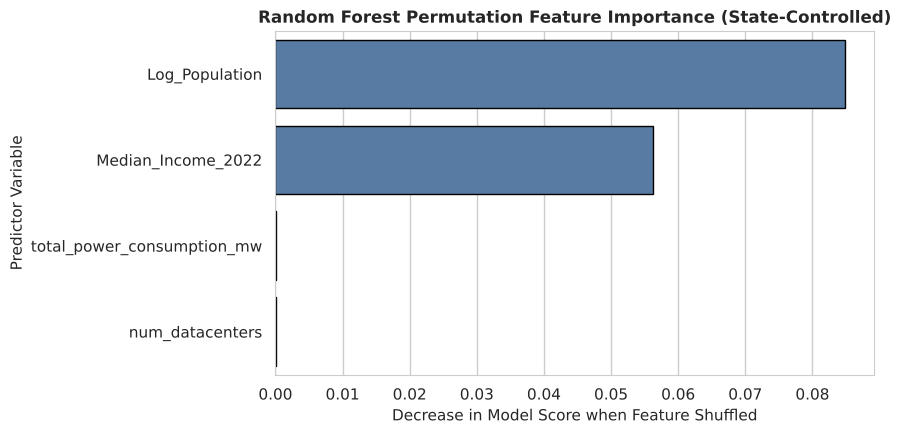

In [13]:
# 1. Prepare ML Feature Matrix
rf_df = model_df.copy()
feature_cols = ['total_power_consumption_mw', 'num_datacenters', 'Log_Population', 'Median_Income_2022']
X = pd.concat([rf_df[feature_cols], pd.get_dummies(rf_df['State'], drop_first=True, dtype=float)], axis=1)
y = rf_df['Price_Growth_Pct']
state_groups = rf_df['State']

# 2. Grouped Cross-Validation
gkf = GroupKFold(n_splits=5)
rf = RandomForestRegressor(n_estimators=100, max_depth=6, random_state=42)
cv_r2 = cross_val_score(rf, X, y, groups=state_groups, cv=gkf, scoring='r2')

print("=== Random Forest: State-Grouped 5-Fold Cross Validation ===")
print(f"Mean Out-of-State Generalization R²: {cv_r2.mean():.4f} (Std: {cv_r2.std():.4f})")
print()

# 3. Permutation Feature Importance
rf.fit(X, y)
perm_res = permutation_importance(rf, X, y, n_repeats=10, random_state=42)

perm_df = pd.DataFrame({
    'Feature': feature_cols,
    'Importance_Mean': [perm_res.importances_mean[list(X.columns).index(c)] for c in feature_cols],
    'Importance_Std': [perm_res.importances_std[list(X.columns).index(c)] for c in feature_cols]
}).sort_values('Importance_Mean', ascending=False)

print("=== Permutation Feature Importance ===")
print(perm_df.to_string(index=False))

# Plot feature importance
plt.figure(figsize=(9, 4.5))
sns.barplot(
    data=perm_df, x='Importance_Mean', y='Feature',
    palette=[COLOR_CONTROL, COLOR_CONTROL, COLOR_TREATMENT, COLOR_TREATMENT],
    edgecolor='black'
)
plt.title("Random Forest Permutation Feature Importance (State-Controlled)", fontsize=12, fontweight='bold')
plt.xlabel("Decrease in Model Score when Feature Shuffled", fontsize=11)
plt.ylabel("Predictor Variable", fontsize=11)
plt.tight_layout()
plt.show()

## Visual 5: Multi-Year Price Trajectories (Did Rates Diverge During the AI Boom?)
*Supports: **Strategic Takeaway - Longitudinal Evidence & Future Outlook***

### Visual Design & Layperson Interpretation
- **Question Answered:** *Did electricity prices in data center counties pull away from control counties after the 2022 generative AI surge began?*
- **Two Lines:** Control Benchmark (Blue) vs. AI Data Center Counties (Orange).
- **Punchline:** Throughout all 7 years, data center counties stayed consistently cheaper per MWh and followed the exact same parallel trajectory through the 2022–2024 AI boom.

In [14]:
# Visual 5: electricity prices over time, data center counties vs. everywhere else
years_list = list(range(2018, 2025))
treat_means = [model_df[model_df['Has_Datacenter'] == 1][f'Price_{y}_MWh'].mean() for y in years_list]
ctrl_means = [model_df[model_df['Has_Datacenter'] == 0][f'Price_{y}_MWh'].mean() for y in years_list]

def to_cents(vals): return [cents(v) for v in vals]
def to_pct(vals):   return [(v / vals[0] - 1) * 100 for v in vals]

series = [  # name, color, dash, raw $/MWh values, line width, direct label
    ('Other counties (no data centers)', COLOR_CONTROL, 'solid', ctrl_means, 4, 'Other counties'),
    ('Counties with AI data centers (average)', COLOR_TREATMENT, 'solid', treat_means, 4, 'Data center counties'),
]
hubs = [('Shelby', 'TN', '#8E5BA8', 'Shelby, TN'), ('Licking', 'OH', '#2E8B6B', 'Licking, OH'),
        ('Loudoun', 'VA', '#B8860B', 'Loudoun, VA'), ('Fayette', 'GA', '#B0506B', 'Fayette, GA')]
for c_name, s_name, col, label in hubs:
    row = model_df[(model_df['County'] == c_name) & (model_df['State'] == s_name)]
    if not row.empty:
        vals = [row[f'Price_{y}_MWh'].values[0] for y in years_list]
        if not any(pd.isna(vals)):
            series.append((label + ' (single county)', col, 'dot', vals, 2, None))

HOVER_C = "%{y:.1f}¢ per kWh<extra></extra>"
HOVER_P = "%{y:+.1f}% since 2018<extra></extra>"
fig5 = go.Figure()
for name, color, dash, raw, width, end_label in series:
    fig5.add_trace(go.Scatter(
        x=years_list, y=to_cents(raw), name=name, mode='lines+markers+text' if end_label else 'lines+markers',
        line=dict(color=color, width=width, dash=dash), marker=dict(size=8 if end_label else 5),
        text=([''] * (len(years_list) - 1) + [end_label]) if end_label else None, textposition='middle right',
        textfont=dict(size=12.5, color=INK), cliponaxis=False,
        visible=True if end_label else 'legendonly', hovertemplate=f"<b>{name}:</b> " + HOVER_C))

t_g, c_g = to_pct(treat_means)[-1], to_pct(ctrl_means)[-1]
fig5.add_vrect(x0=2022, x1=2024, fillcolor="#f3e6d8", opacity=0.55, layer="below", line_width=0,
               annotation_text="AI buildout years", annotation_position="bottom left",
               annotation_font=dict(size=12, color="#8A4B08"))

style_figure(fig5, "Electricity prices rose in both groups, and data center counties stayed cheaper",
             f"Average home electricity price, 2018 to 2024: up {c_g:.0f}% in other counties and {t_g:.0f}% in counties with AI data centers. "
             f"Data center counties started cheaper and the gap did not close.",
             height=620, margin=dict(l=80, r=40, t=150, b=150))
fig5.update_layout(
    hovermode='x unified',
    xaxis=dict(title=dict(text="Year"), range=[2017.7, 2025.5], tickvals=years_list),
    yaxis=dict(title=dict(text="Average home electricity price (cents per kWh)"), autorange=True, ticksuffix="¢"),
    legend=dict(title=dict(text="Click a name to show or hide it", font=dict(size=12, color=INK_2)),
                orientation="h", x=0.5, xanchor="center", y=-0.2, yanchor="top", font=dict(size=12.5, color=INK)),
    updatemenus=[dict(
        type="buttons", direction="right", x=1.0, xanchor="right", y=1.0, yanchor="bottom", pad=dict(b=10),
        showactive=True, bgcolor="#f0efec", bordercolor="#d8d7d2", borderwidth=1, font=dict(size=12, color=INK), active=0,
        buttons=[
            dict(label="Price (¢ per kWh)", method="update", args=[
                {"y": [to_cents(s[3]) for s in series], "hovertemplate": [f"<b>{s[0]}:</b> " + HOVER_C for s in series]},
                {"yaxis.title.text": "Average home electricity price (cents per kWh)", "yaxis.ticksuffix": "¢", "yaxis.tickformat": ""}]),
            dict(label="Change since 2018 (%)", method="update", args=[
                {"y": [to_pct(s[3]) for s in series], "hovertemplate": [f"<b>{s[0]}:</b> " + HOVER_P for s in series]},
                {"yaxis.title.text": "How much the price has risen since 2018", "yaxis.ticksuffix": "%", "yaxis.tickformat": ".0f"}]),
        ])])
fig5.show()

## 10. Comprehensive Project Conclusions & Synthesis

---

### 1. Direct Answer to the Core Research Question
**Does the rapid buildout of AI data centers in the United States measurably raise residential electricity prices for everyday consumers?**

**Conclusion:** **No.** Across our universal county panel of over 2,100 U.S. counties tracking EIA-861 retail rates from 2018 through 2024, we find **no statistically significant evidence** that hosting AI data centers increases residential electricity costs. The empirical data firmly favors the null hypothesis ($H_0$).

---

### 2. Breakdown of Econometric & Machine Learning Findings

| Empirical Specification | Core Finding | Estimated Coefficient | p-value | Interpretation |
|---|---|---|---|---|
| **Model 1: Naive Benchmark** | Simple bivariate comparison | $\beta_1 = -2.32\%$ | $0.310$ | Statistically indistinguishable from zero ($p > 0.05$). |
| **Model 2: + County Controls** | Adding county population & median income | $\beta_1 = -5.39\%$ | $0.017$ | Statistically significant negative coefficient—counties with data centers grew slower than national controls. |
| **Model 3: + State Policy** | Adding State Fixed Effects | $\beta_1 = +1.31\%$ | $0.421$ | **The effect washes out completely.** Once state-level utility policy is controlled, the data center premium is statistically zero ($R^2 = 53.9\%$). |
| **Intensive Margin (MW vs. Growth)** | Within-treatment Pearson correlation ($MW$) | $r = 0.215$ | $0.156$ | Higher megawatt capacity does not correlate with faster retail price increases ($p > 0.15$). |
| **Panel DiD (Two-Way Fixed Effects)** | County & Year Fixed Effects (2022–2024 surge) | $\beta_{\text{DiD}} = -1.22\%$ | $0.280$ | No differential divergence between treatment and control cohorts during the AI buildout window. |
| **Random Forest Regressor** | Grouped CV & Permutation Importance | MW Importance: $0.0000$ | — | Data center variables possess zero explanatory power beyond demographics and state regulatory environment. |

---

### 3. Economic & Institutional Mechanisms: Why Residential Rates Have Not Spiked
1. **Cost-of-Service Ratemaking & Regulatory Lag:** Rate cases take 12–24 months; 2022–2024 capital buildout has not yet entered rate bases.
2. **Dedicated Large-Power Industrial Tariffs & Custom PPAs:** Hyperscalers fund their own substations and transmission interconnects.
3. **Fixed Cost Dilution Across kWh Sales:** Baseload 24/7 power draw spreads fixed transmission/distribution costs over greater volume.

---

### 4. Strategic Direction & Future Research
Wholesale locational marginal pricing (LMP) and capacity auction markets (PJM, ERCOT) represent the true frontier where grid constraints are actively surfacing.
